# 第3节. Think In LangGraph

前两节我们学习了 LangGraph 的三要素和七种编排模式，它们解决的是「怎么做」的问题。

本节换个角度，从零构建一个客户支持 Agent 的完整流程，理解 LangGraph 背后的思维框架——「怎么想」。

LangGraph 构建 Agent 有5个核心阶段：

* 将任务拆解为一个个离散的节点，Node
* 明确每个节点的具体任务
* 设计节点中流转的数据格式，State
* 编写节点函数，做好异常处理
* 连接节点，形成图，Graph

传统 Prompt Chaining 是线性的 A→B→C，但真实世界的 Agent 是有分支、有回路、有人工介入的图结构。

要正确创建这个图就必须学会LangGraph的思维，接下来我们就一个客户支持的EmailAgent为例来学习如何Thinking in LangGraph.


# 0. 客户支持 Agent：需求分析

假设我们要构建一个自动处理客服邮件的 Agent，它需要：

* 读取收件箱中的新邮件
* 按紧急程度和主题分类
* 搜索知识库文档寻找答案
* 撰写回复草稿
* 复杂问题升级给人工处理
* 必要时安排跟进

以下五个场景代表了不同类型的问题：

| 场景 | 类型 | 处理策略 |
|------|------|----------|
| 密码重置 | 简单问题 | 查文档 → 自动回复 |
| PDF导出崩溃 | Bug | 创建工单 → 人工审核 |
| 重复扣款 | 紧急账单 | 直接人工处理 |
| 暗黑模式功能 | 功能请求 | 查文档 → 标记feature |
| API间歇性504 | 复杂技术 | 直接人工处理 |

**核心观察**：不同的问题类型走不同的处理路径 —— 这就是我们需要**图**而不是**链**的原因。


# 1. 设计工作流

首先不着急写代码，先梳理业务，把业务流程用图画出来：

七个节点，虚线表示条件路径。不过，我们**不定义条件边**，而是把决策定义在节点内部。
###### **_（把决策定义在内部使用Command模式）_**

每个节点只做一件事：

| 节点 | 职责 | 决策？ |
|------|------|--------|
| 读取邮件 | 解析邮件内容和发件人 | 否 |
| 意图识别 | LLM分类意图+紧急度，决定下一步路径 | **是** |
| 文档搜索 | 搜索知识库 | 否 |
| BUG跟踪 | 创建/更新 Bug 工单 | 否 |
| 生成草稿 | LLM生成回复草稿，判断是否需要人工审核 | **是** |
| 人工审核 | 暂停等待人工审批 | 否 |
| 发送 | 发送邮件 | 否 |


# 2. 理清节点的职责

接下来还不是写代码，而是先明确每个节点的输入、输出、失败策略。这决定了你的 State 设计和 Node 的错误处理架构。而这些跟节点的职责类型有关。

LangGraph 中有节点按照职责可以分为四类：

* **LLM节点**：主要职责是理解、分析、生成
* **Data节点**：主要职责是检索外部数据
* **Action节点**：职责是执行外部操作
* **Human节点**：职责是负责人机交互


## 2.1 LLM 节点

| 节点 | 静态上下文（Prompt模板） | 动态上下文（State） | 期望输出 |
|------|--------------------------|---------------------|----------|
| 意图识别 | 分类类别、紧急度定义 | 邮件内容、发件人 | 结构化分类结果 + 路由 |
| 生成草稿 | 语气指南、公司政策 | 分类结果、搜索结果、客户历史 | 专业回复草稿 |


## 2.2 Data 节点

| 节点 | 查询参数 | 重试策略 | 缓存 |
|------|----------|----------|------|
| 文档检索 | 从意图和主题构建查询 | 快速失败重试 | 常用查询永久缓存 |
| 客户信息查询 | 客户邮箱或ID | 重试+降级到基本信息 | 客户信息可设置TTL缓存 |


## 2.3 Action 节点

| 节点 | 执行时机 | 重试策略 | 幂等性 |
|------|----------|----------|--------|
| 发送邮件 | 审批之后 | 网络问题快速失败重试 | 不缓存，每次唯一 |
| BUG跟踪 | 意图为bug时 | 必须重试，不能丢失BUG报告 | 返回Ticket ID |


## 2.4 Human 节点

| 节点 | 呈现给人工的上下文 | 预期输入 | 触发条件 |
|------|---------------------|----------|----------|
| 人工确认 | 原邮件 + 草稿 + 紧急度 + 分类 | 是否批准或修改后的回复 | 高紧急度、复杂问题 |


# 3. 设计 State

State 是所有节点共享的"工作笔记本"。怎么判断一个字段要不要放 State？

**原则**：如果下游节点需要用它做决策或处理，就入 State。如果能从其他字段推导出来，就不存。

对于我们的Email Agent，我们需要存入State的信息包括：

* 原始邮件及发件人信息（之后无法重建）
* 分类结果（被后续多个节点所需）
* 搜索结果和客户数据（重新获取成本较高）
* 回复邮件的草稿（需在评审期间展示）


In [1]:
# 可以访问python运行环境的一些信息
import sys
# Windows 控制台默认 GBK 编码，打印表情/特殊字符会报错，这里统一改用 UTF-8
if hasattr(sys.stdout, "reconfigure"):  # 标准输出 sys.stdout 处理Windows 控制台的编码问题
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
if hasattr(sys.stderr, "reconfigure"): # 标准错误 sys.stderr 处理Windows 控制台的编码问题
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")
from typing import TypedDict, Literal, Optional
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage, HumanMessage
from langchain.chat_models import init_chat_model
from IPython.display import Image, display
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import random

load_dotenv()

llm = init_chat_model("deepseek-chat")

# 把你创建好的 LangGraph 工作流画成一张图，方便你“看见”整个工作流的结构
def display_graph(graph, xray=False):
    display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))

# 意图识别的结构化输出 AI 对一封邮件进行分类后，要产生什么结果
class EmailClassification(TypedDict):
    intent: Literal["question", "bug", "billing", "feature", "complex"]
    urgency: Literal["low", "medium", "high", "critical"]
    topic: str
    summary: str

# 邮件State  整个工作流运行过程中，Agent 的“共享记忆/工作台”。
class EmailAgentState(TypedDict):
    # 原始输入
    email_content: str
    sender_email: str
    email_id: str
    # 分类结果 分类 Node 必须产生一份标准格式的分类结果,因此定义了上述EmailClassification字段
    classification: EmailClassification | None # EmailAgentState 里面有一个叫 classification 的字段，而这个字段的数据结构应该符合 EmailClassification
    # 外部数据
    search_results: list[str] | None
    customer_history: dict | None
    # 生成内容
    draft_response: str | None
    messages: list | None

print("State定义完成")

State定义完成


# 4. 构建节点

分析好节点职责，接下来就是创建节点了。节点就是一个Python函数，接收当前State，返回State更新。

我们使用 **Command** 在节点内部做路由决策（而不是单独的条件边），这样决策逻辑与节点职责紧密绑定。


## 4.1 读取邮件节点（Data/Action）


In [2]:
# State 给 Node 提供输入，Node 执行完以后返回的数据又会更新 State
def read_email(state: EmailAgentState) -> dict:
    """解析邮件内容和发件人"""
    print(f"  [Read] 收到邮件: {state['email_id']}")
    # 实际场景中这里会调用邮件API读取内容
    # 本例中假设内容已通过invoke传入
    return {}

## 4.2 意图识别节点（LLM + 路由决策）


###### **_总结为决策型node_**

In [3]:
# 定义了一个具有完整职责的分类 Node(让一个 Node 既负责“理解邮件”，又负责“决定下一步”)
# LLM 分类 → 结构化输出 → 更新 State → Node 内部决策 → Command 路由到不同 Node

# 结构化输出模型 定义 LLM 进行“邮件分类”时必须输出的数据结构，并把普通 LLM 包装成一个能够按照这个结构返回结果的 classifier

# 准别分类器
class ClassificationResult(BaseModel):
    # 邮件意图必须是规定的五种之一
    intent: Literal["question", "bug", "billing", "feature", "complex"] = Field(
        description="邮件意图分类"
    )
    # 定义紧急程度
    urgency: Literal["low", "medium", "high", "critical"] = Field(
        description="紧急程度"
    )
    # 邮件的主题是什么
    topic: str = Field(description="邮件主题关键词")
    # 用一句话总结客户问题
    summary: str = Field(description="一句话摘要")
# 规定LLM必须给出，结构化输出
classifier = llm.with_structured_output(ClassificationResult)

# 真正定义node
def classify_intent(state: EmailAgentState) -> Command:
    """LLM分类意图+紧急度，并决定下一步路径"""
    # 得到LLM结构化结果
    result = classifier.invoke([
        SystemMessage(content="""你是客服邮件分类专家。根据邮件内容分类：
- question: 简单问题（如密码重置、如何使用）
- bug: 功能故障/崩溃
- billing: 账单/扣款问题
- feature: 功能请求/建议
- complex: 复杂技术问题
紧急度：critical(立即处理), high(今日内), medium(本周), low(可延后)
"""),
        HumanMessage(content=f"发件人: {state['sender_email']}\n内容: {state['email_content']}")
    ])
    
    classification = {
        "intent": result.intent,
        "urgency": result.urgency,
        "topic": result.topic,
        "summary": result.summary
    }
    print(f"  [Classify] intent={result.intent}, urgency={result.urgency}")
    
    # 根据意图路由
    intent = result.intent
    if intent == "bug":
        next_node = "bug_tracking"
    elif intent in ("question", "feature"):
        next_node = "search_docs"
    else:  # billing / complex → 直接生成草稿后走人工
        next_node = "draft_response"
    
    print(f"  [Classify] ->路由到: {next_node}")
    return Command(
        update={"classification": classification},
        goto=next_node  # 动态进入下一节点
    )

## 4.3 文档搜索节点（Data）

###### **_总结为：工具/数据处理型 Node_**


In [4]:
# 模拟知识库
KNOWLEDGE_BASE = {
    "密码": "重置密码请访问 https://app.example.com/reset-password ，输入注册邮箱即可收到重置链接。",
    "导出": "PDF导出功能需在设置中开启「高级导出」。若崩溃请更新到最新版本。",
    "暗黑": "暗黑模式可在「设置 → 外观 → 主题」中开启，支持跟随系统。",
    "API": "API 504错误通常是超时导致，建议增加重试机制并检查网络稳定性。",
}

def search_docs(state: EmailAgentState) -> Command:
    """搜索知识库"""
    topic = state["classification"]["topic"] if state["classification"] else ""
    content = state["email_content"]
    
    # 简单关键词匹配模拟搜索
    results = []
    for key, doc in KNOWLEDGE_BASE.items():
        if key in content or key in topic:
            results.append(doc)
    
    if not results:
        results = ["未找到直接相关文档，建议人工处理。"]
    
    print(f"  [Search] 找到 {len(results)} 条相关文档")
    return Command(
        update={"search_results": results},
        goto="draft_response"  # 固定进入draft_response 节点
    )

## 4.4 BUG跟踪节点（Action）


In [5]:
def bug_tracking(state: EmailAgentState) -> Command:
    """创建/更新 Bug 工单"""
    ticket_id = f"BUG-{random.randint(20000, 99999)}"
    print(f"  [BugTrack] 创建工单 {ticket_id}")
    # 实际场景会调用工单系统API
    history = state.get("customer_history") or {}
    history["ticket_id"] = ticket_id
    return Command(
        update={"customer_history": history},
        goto="draft_response"
    )

## 4.5 生成草稿节点（LLM + 路由决策）


In [6]:
# 根据前面收集的信息生成回复，然后判断“这封回复能不能自动发，还是必须人工审核”

def draft_response(state: EmailAgentState) -> Command:
    """LLM生成回复草稿，并判断是否需要人工审核"""
    # 从state读取分类结果
    classification = state["classification"] or {}
    # 读取知识库搜索结果
    search = state.get("search_results") or []
    # 读取客户历史
    history = state.get("customer_history") or {}

   # 构建context,把前面所有node产生的信息整合起来
    context = f"""
邮件内容: {state['email_content']}
发件人: {state['sender_email']}
分类: {classification.get('intent')} / 紧急度: {classification.get('urgency')}
知识库结果: {search}
工单信息: {history}
"""
    # 调用LLM生成回复
    msg = llm.invoke([
        SystemMessage(content="""你是专业客服，请根据上下文撰写礼貌、专业的中文回复邮件。
要求：简洁、有同理心、给出明确下一步。不要使用Markdown标题，直接写正文。
"""),
        HumanMessage(content=context)
    ])
    
    draft = msg.content
    print(f"  [Draft] 回复已生成 ({len(draft)} 字符)")
    
    # 判断是否需要人工审核
    urgency = classification.get("urgency", "low")
    intent = classification.get("intent", "question")
    
    if urgency in ("high", "critical") or intent in ("billing", "complex", "bug"):
        next_node = "human_review"
        print(f"  [Draft] -> 路由到: human_review")
    else:
        next_node = "send_email"
        print(f"  [Draft] -> 路由到: send_email")
    
    return Command(
        update={"draft_response": draft},
        goto=next_node
    )

## 4.6 人工审核节点（Human）


In [7]:
def human_review(state: EmailAgentState) -> Command:
    """暂停等待人工审批"""
    # 使用 interrupt 暂停执行，等待外部 resume
    decision = interrupt({
        "email_id": state["email_id"],
        "sender": state["sender_email"],
        "classification": state["classification"],
        "draft": state["draft_response"],
        "actions": ["approve", "edit", "reject"],
        "message": "请审核此回复草稿，选择 approve / edit / reject"
    })
    
    action = decision.get("action", "approve")
    
    if action == "edit":
        edited = decision.get("edited_response", state["draft_response"])
        print(f"  [Human] 人工修改了草稿")
        return Command(
            update={"draft_response": edited},
            goto="send_email"
        )
    elif action == "reject":
        print(f"  [Human] 人工拒绝发送")
        return Command(goto=END)
    else:  # approve
        print(f"  [Human] 人工批准发送")
        return Command(goto="send_email")

## 4.7 发送邮件节点（Action）


In [8]:
def send_email(state: EmailAgentState) -> dict:
    """发送邮件"""
    print(f"  [Send] 发送回复邮件给{state['sender_email']}成功...")
    # 实际场景调用邮件发送API
    return {}

# 5. 连接节点，形成图

现在把所有节点用边连接起来。注意：

* 意图识别和生成草稿节点内部已经用 `Command(goto=...)` 做了路由，所以不需要额外的条件边
* 其他节点用普通边连接
* 使用 Checkpointer 支持 Human-in-the-loop 的断点恢复

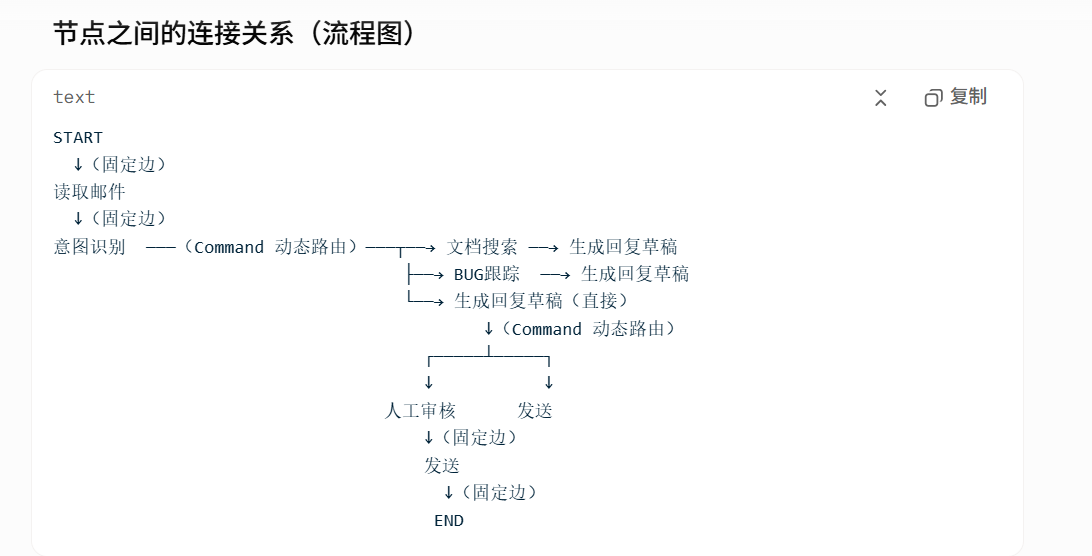


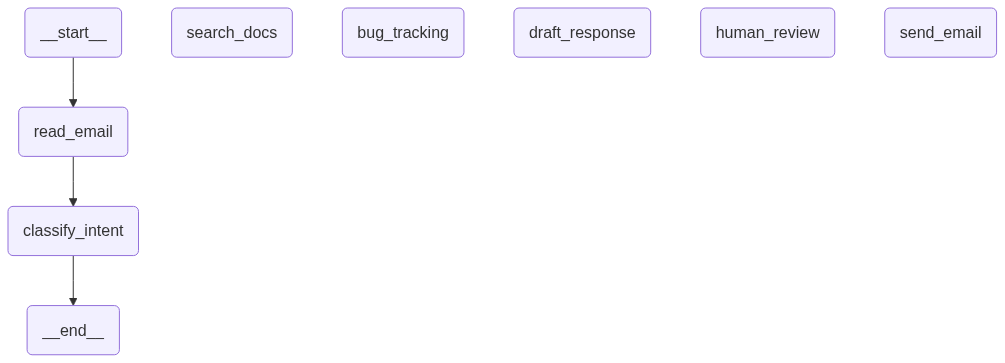

Email Agent Graph 构建完成


In [9]:
# 构建图
builder = StateGraph(EmailAgentState)

builder.add_node("read_email", read_email)
builder.add_node("classify_intent", classify_intent)
builder.add_node("search_docs", search_docs)
builder.add_node("bug_tracking", bug_tracking)
builder.add_node("draft_response", draft_response)
builder.add_node("human_review", human_review)
builder.add_node("send_email", send_email)

# 固定边
builder.add_edge(START, "read_email")
builder.add_edge("read_email", "classify_intent")
# classify_intent / draft_response / human_review 内部用 Command 路由
# search_docs / bug_tracking 内部也用 Command 跳到 draft_response
builder.add_edge("send_email", END)

# 编译（必须带 checkpointer 才能支持 interrupt）
app = builder.compile(checkpointer=InMemorySaver())

display_graph(app)
print("Email Agent Graph 构建完成")

# 6. 测试不同场景

我们用前面定义的五个场景来验证不同路径。


## 6.1 简单问题（密码重置 → 查文档 → 自动回复）


###### 用户给的问题（邮件内容）不同 → LLM 分类结果不同 → 中间走的节点不同（分支路径不同）。
######  **_固定不变的节点：_**
######  **_读取邮件（入口）：永远是第一个执行的节点_**
######  **_发送邮件（出口）：最终都会走到这里（无论中间走了哪条路）_**

In [10]:
print("=== 场景1: 简单问题（查文档 → 自动回复）===\n")
config1 = {"configurable": {"thread_id": "t1"}}
r1 = app.invoke({
    "email_content": "你好，我忘记密码了，怎么重置？",
    "sender_email": "alice@example.com",
    "email_id": "email-001",
    "classification": None,
    "search_results": None,
    "customer_history": None,
    "draft_response": None,
    "messages": None
}, config1)

print(f"\n最终回复:\n{r1.get('draft_response', '(无)')}")

=== 场景1: 简单问题（查文档 → 自动回复）===

  [Read] 收到邮件: email-001
  [Classify] intent=question, urgency=low
  [Classify] ->路由到: search_docs
  [Search] 找到 1 条相关文档
  [Draft] 回复已生成 (174 字符)
  [Draft] -> 路由到: send_email
  [Send] 发送回复邮件给alice@example.com成功...

最终回复:
您好，

感谢您的来信。

要重置密码，请您访问以下链接：https://app.example.com/reset-password ，输入您注册时使用的邮箱地址，系统会立即发送一封重置密码的邮件到您的邮箱。请按照邮件中的指示操作即可完成重置。

如果您在操作过程中遇到任何问题，或未收到邮件，请随时回复我们，我们会尽快协助您处理。

祝您顺利！


## 6.2 BUG报告（建工单 → 回复 → 人工审核）


In [11]:
print("\n=== 场景2: Bug报告（建工单 → 回复）===\n")
config2 = {"configurable": {"thread_id": "t2"}}
r2 = app.invoke({
    "email_content": "PDF导出功能每次都会崩溃，急需修复！",
    "sender_email": "jane@corp.com",
    "email_id": "email-002",
    "classification": None,
    "search_results": None,
    "customer_history": None,
    "draft_response": None,
    "messages": None
}, config2)

print(f"\n回复草稿: {str(r2.get('draft_response', '(等待人工审核)'))[:200]}...")


=== 场景2: Bug报告（建工单 → 回复）===

  [Read] 收到邮件: email-002
  [Classify] intent=bug, urgency=high
  [Classify] ->路由到: bug_tracking
  [BugTrack] 创建工单 BUG-37603
  [Draft] 回复已生成 (270 字符)
  [Draft] -> 路由到: human_review

回复草稿: 您好Jane，

非常理解PDF导出功能崩溃给您带来的困扰，也感谢您第一时间反馈这个问题。

我们已经将您报告的情况记录为紧急工单（编号：BUG-37603），并已转交技术团队优先排查。接下来我们会在4小时内复现问题、定位原因，并尽快给出修复方案或临时替代操作建议。

您方便的话，可以再提供一下：
1. 触发崩溃的是单个文件还是所有文件？
2. 您的操作系统和软件版本号是什么？

这些信息能帮助我...


## 6.3 紧急账单问题（直接升级人工审核）


In [12]:
print("\n=== 场景3: 账单问题（直接升级人工审核）===\n")
config3 = {"configurable": {"thread_id": "t3"}}
r3 = app.invoke({
    "email_content": "我被重复扣款了！这是什么情况！请立刻处理！",
    "sender_email": "jack@corp.com",
    "email_id": "vip-email-003",
    "classification": None,
    "search_results": None,
    "customer_history": None,
    "draft_response": None,
    "messages": None
}, config3)

print("（因紧急度高，已进入人工审核，等待 resume）")


=== 场景3: 账单问题（直接升级人工审核）===

  [Read] 收到邮件: vip-email-003
  [Classify] intent=billing, urgency=high
  [Classify] ->路由到: draft_response
  [Draft] 回复已生成 (269 字符)
  [Draft] -> 路由到: human_review
（因紧急度高，已进入人工审核，等待 resume）


In [15]:
# 模拟人工审核并继续执行流程
# 模拟人工审核：edit 后发送
from langgraph.types import Command

r4 = app.invoke(
    Command(resume={
        "action": "edit",  # 表示人工选择了“编辑”
        # 人工修改后的回复内容
        "edited_response": """尊敬的VIP客户jack，

非常抱歉给您带来不便！我们已紧急核查您的账户，确认存在重复扣款。我们将立即为您办理退款，预计1小时内原路返回。如有其他问题，请随时联系我们。再次感谢您的耐心！

黑马程序员"""
    }),
    config3
)

print(f"\n最终发送的回复:\n{r4.get('draft_response', '')}")


最终发送的回复:
尊敬的VIP客户jack，

非常抱歉给您带来不便！我们已紧急核查您的账户，确认存在重复扣款。我们将立即为您办理退款，预计1小时内原路返回。如有其他问题，请随时联系我们。再次感谢您的耐心！

黑马程序员


# 7. Think In LangGraph 思维框架总结

构建复杂 Agent 时，请遵循以下思考顺序：

1. **需求分析**：列出所有业务场景，观察是否存在不同路径（如果都是线性，用链即可；有分支就需要图）
2. **画流程图**：先在纸上画出节点和虚线条件路径，再决定哪些决策放在节点内部（Command），哪些用条件边
3. **节点职责分类**：把每个节点归入 LLM / Data / Action / Human 四类，明确输入、输出、失败策略
4. **设计 State**：只存下游真正需要的字段；能推导的不存；高成本获取的要缓存
5. **编写节点**：每个节点只做一件事；路由决策用 `Command(goto=...)` 内聚在节点内
6. **连接成图 + Checkpointer**：支持 Human-in-the-loop 的断点恢复
7. **场景测试**：用真实业务场景验证每条路径

**核心原则**：

* 节点职责单一
* 决策靠近数据（在产生分类结果的节点内就做路由）
* State 是共享笔记本，不是垃圾桶
* Human 节点用 `interrupt` + `Command(resume=...)` 实现真正的人机协作


---

## 本节练习建议

1. 增加「功能请求」路径：搜索文档后标记为 feature request，并自动回复感谢。
2. 为文档搜索节点添加真实向量检索（或模拟缓存）。
3. 在生成草稿节点中加入客户历史（VIP 客户使用更亲切的语气）。
4. 实现完整的 reject 流程：人工拒绝后记录原因并结束。
5. 用 `stream` 观察每个节点的中间状态变化。
